# Importing Libraries

In [1]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

# Pre-Processing

In [2]:
# Config
data_dir = 'Image'
image_size = 64  # Resize all images to 64x64
X = []
y = []
labels = sorted(os.listdir(data_dir))  # A–Z
label_dict = {label: idx for idx, label in enumerate(labels)}

# Loading images
for label in labels:
    path = os.path.join(data_dir, label)
    for img_name in os.listdir(path):
        img_path = os.path.join(path, img_name)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)  # grayscale
        img = cv2.resize(img, (image_size, image_size))
        X.append(img)
        y.append(label_dict[label])

# Converting to numpy arrays and normalize
X = np.array(X).reshape(-1, image_size, image_size, 1) / 255.0
y = to_categorical(np.array(y))

print(f"Total images: {len(X)}")
print(f"Labels shape: {y.shape}")

Total images: 6732
Labels shape: (6732, 26)


## Splitting Data

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=57, stratify=y)

# MODEL

In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(image_size, image_size, 1)),
    MaxPooling2D(2, 2),
    
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(len(labels), activation='softmax')
])
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

C:\Users\Administrator\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Training

In [5]:
history = model.fit(X_train, y_train,epochs=25,validation_data=(X_test, y_test))
model.save("sign_language_model.h5")

Epoch 1/25
169/169 ━━━━━━━━━━━━━━━━━━━━ 98s 541ms/step - accuracy: 0.0876 - loss: 3.1615 - val_accuracy: 0.5702 - val_loss: 1.6867
Epoch 2/25
169/169 ━━━━━━━━━━━━━━━━━━━━ 126s 449ms/step - accuracy: 0.5668 - loss: 1.5223 - val_accuracy: 0.7877 - val_loss: 0.7949
Epoch 3/25
169/169 ━━━━━━━━━━━━━━━━━━━━ 93s 516ms/step - accuracy: 0.7374 - loss: 0.8920 - val_accuracy: 0.8641 - val_loss: 0.5360
Epoch 4/25
169/169 ━━━━━━━━━━━━━━━━━━━━ 132s 456ms/step - accuracy: 0.8316 - loss: 0.5688 - val_accuracy: 0.8998 - val_loss: 0.3672
Epoch 5/25
169/169 ━━━━━━━━━━━━━━━━━━━━ 95s 530ms/step - accuracy: 0.8803 - loss: 0.3869 - val_accuracy: 0.9169 - val_loss: 0.2933
Epoch 6/25
169/169 ━━━━━━━━━━━━━━━━━━━━ 133s 474ms/step - accuracy: 0.9133 - loss: 0.2929 - val_accuracy: 0.9272 - val_loss: 0.2677
Epoch 7/25
169/169 ━━━━━━━━━━━━━━━━━━━━ 78s 452ms/step - accuracy: 0.9397 - loss: 0.2126 - val_accuracy: 0.9362 - val_loss: 0.2291
Epoch 8/25
169/169 ━━━━━━━━━━━━━━━━━━━━ 93s 548ms/step - accuracy: 0.9516 - loss

## Plotting Accuracy

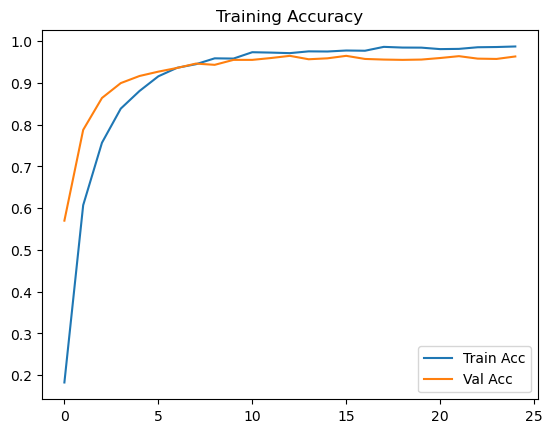

In [6]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Training Accuracy")
plt.legend()
plt.show()